In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from pathlib import Path

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_curve
)

sns.set_theme(style="whitegrid")

In [6]:
ROOT = Path.cwd()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

PROCESSED_PATH = ROOT / "data" / "processed"
MODEL_PATH = ROOT / "models"
FIGURES_PATH = ROOT / "reports" / "figures"

FIGURES_PATH.mkdir(parents=True, exist_ok=True)

# Load test data
data = joblib.load(
    PROCESSED_PATH / "train_test_data.pkl"
)

X_test = data["X_test"]
y_test = data["y_test"]

# Load trained models
logistic_smote = joblib.load(
    MODEL_PATH / "logistic_smote.pkl"
)

logistic_weighted = joblib.load(
    MODEL_PATH / "logistic_weighted.pkl"
)

xgb_model = joblib.load(
    MODEL_PATH / "xgboost_model.pkl"
)

isolation_model = joblib.load(
    MODEL_PATH / "isolation_forest.pkl"
)

print("All models and testing data loaded successfully!")
print("Test dataset shape:", X_test.shape)
print("\nTest class distribution:")
print(y_test.value_counts())

All models and testing data loaded successfully!
Test dataset shape: (56746, 30)

Test class distribution:
Class
0    56651
1       95
Name: count, dtype: int64


In [7]:
models = {
    "Logistic Regression (SMOTE)": logistic_smote,
    "Logistic Regression (Weighted)": logistic_weighted,
    "XGBoost": xgb_model
}

predictions = {}
probabilities = {}

for name, model in models.items():

    predictions[name] = model.predict(X_test)

    # Find the probability column corresponding to fraud (Class 1)
    fraud_index = list(model.classes_).index(1)

    probabilities[name] = model.predict_proba(X_test)[:, fraud_index]

    print(f"{name}: Predictions generated")

Logistic Regression (SMOTE): Predictions generated
Logistic Regression (Weighted): Predictions generated
XGBoost: Predictions generated


In [9]:
# Isolation Forest predictions:
# 1 = Normal
# -1 = Anomaly

if_predictions_raw = isolation_model.predict(X_test)

# Convert to our dataset labels:
# 0 = Genuine
# 1 = Fraud

predictions["Isolation Forest"] = np.where(
    if_predictions_raw == -1, 1, 0
)

# Higher score means more anomalous
probabilities["Isolation Forest"] = (
    -isolation_model.decision_function(X_test)
)

print("Isolation Forest predictions generated!")

Isolation Forest predictions generated!


In [8]:
results = []

for name in predictions:

    y_pred = predictions[name]
    y_score = probabilities[name]

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test, y_pred, zero_division=0
    )
    recall = recall_score(
        y_test, y_pred, zero_division=0
    )
    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )

    pr_auc = average_precision_score(
        y_test, y_score
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "PR-AUC": pr_auc
    })

results_df = pd.DataFrame(results)

display(
    results_df.round(4).sort_values(
        by="PR-AUC",
        ascending=False
    )
)

,Model,Accuracy,Precision,Recall,F1-Score,PR-AUC
2,XGBoost,0.9990,0.6696,0.8105,0.7333,0.8095
0,Logistic Regression (SMOTE),0.9737,0.0530,0.8737,0.1000,0.6769
1,Logistic Regression (Weighted),0.9752,0.0562,0.8737,0.1057,0.6719


In [10]:
for name, y_pred in predictions.items():

    print("\n" + "=" * 65)
    print(name)
    print("=" * 65)

    print(
        classification_report(
            y_test,
            y_pred,
            target_names=["Genuine", "Fraud"],
            zero_division=0
        )
    )


Logistic Regression (SMOTE)
              precision    recall  f1-score   support

     Genuine       1.00      0.97      0.99     56651
       Fraud       0.05      0.87      0.10        95

    accuracy                           0.97     56746
   macro avg       0.53      0.92      0.54     56746
weighted avg       1.00      0.97      0.99     56746


Logistic Regression (Weighted)
              precision    recall  f1-score   support

     Genuine       1.00      0.98      0.99     56651
       Fraud       0.06      0.87      0.11        95

    accuracy                           0.98     56746
   macro avg       0.53      0.92      0.55     56746
weighted avg       1.00      0.98      0.99     56746


XGBoost
              precision    recall  f1-score   support

     Genuine       1.00      1.00      1.00     56651
       Fraud       0.67      0.81      0.73        95

    accuracy                           1.00     56746
   macro avg       0.83      0.90      0.87     56746
weig

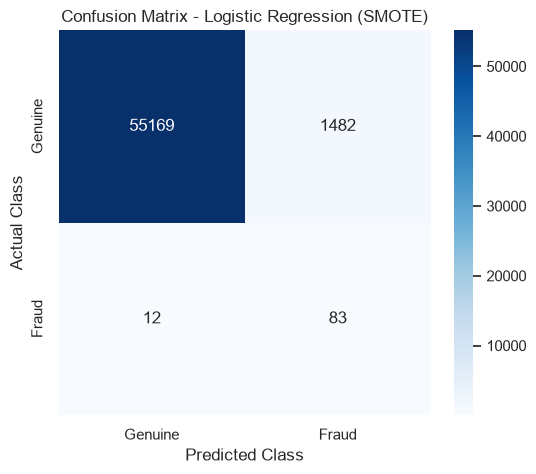

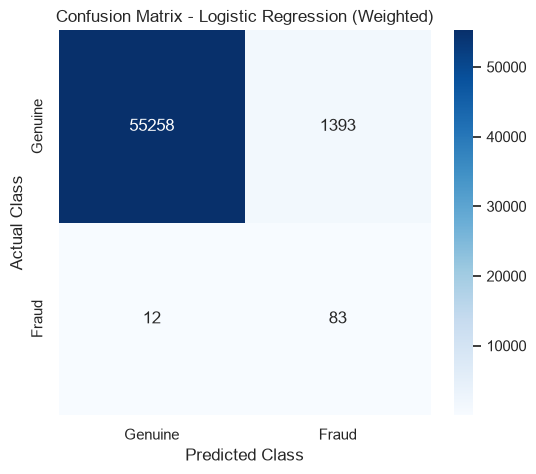

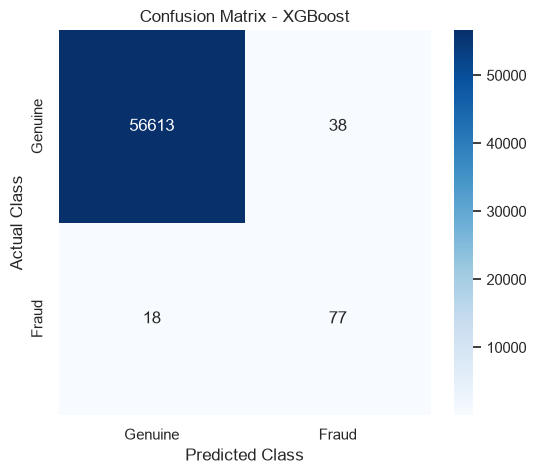

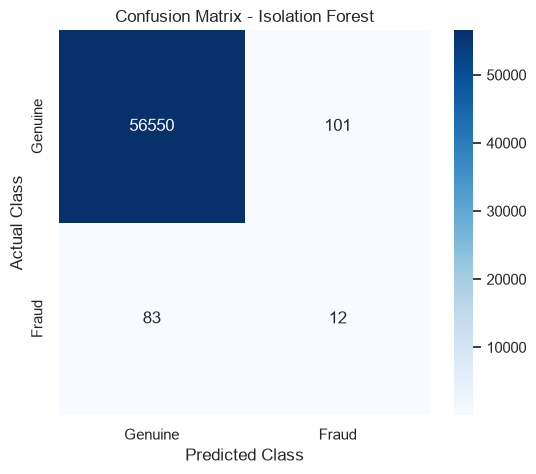

In [7]:
for name, y_pred in predictions.items():

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Genuine", "Fraud"],
        yticklabels=["Genuine", "Fraud"]
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")

    filename = (
        name.lower()
        .replace(" ", "_")
        .replace("(", "")
        .replace(")", "")
        .replace("-", "_")
    )

    plt.savefig(
        FIGURES_PATH / f"confusion_matrix_{filename}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

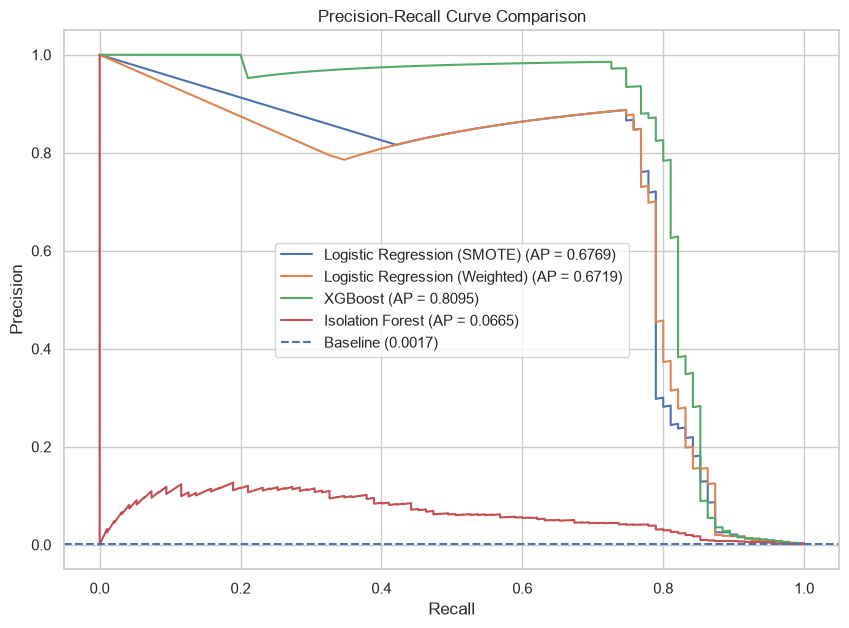

In [11]:
plt.figure(figsize=(10, 7))

for name, y_score in probabilities.items():

    precision_values, recall_values, thresholds = (
        precision_recall_curve(y_test, y_score)
    )

    ap_score = average_precision_score(
        y_test,
        y_score
    )

    plt.plot(
        recall_values,
        precision_values,
        label=f"{name} (AP = {ap_score:.4f})"
    )

# Baseline: proportion of fraud in test data
baseline = y_test.mean()

plt.axhline(
    baseline,
    linestyle="--",
    label=f"Baseline ({baseline:.4f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve Comparison")

plt.legend()
plt.grid(True)

plt.savefig(
    FIGURES_PATH / "precision_recall_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

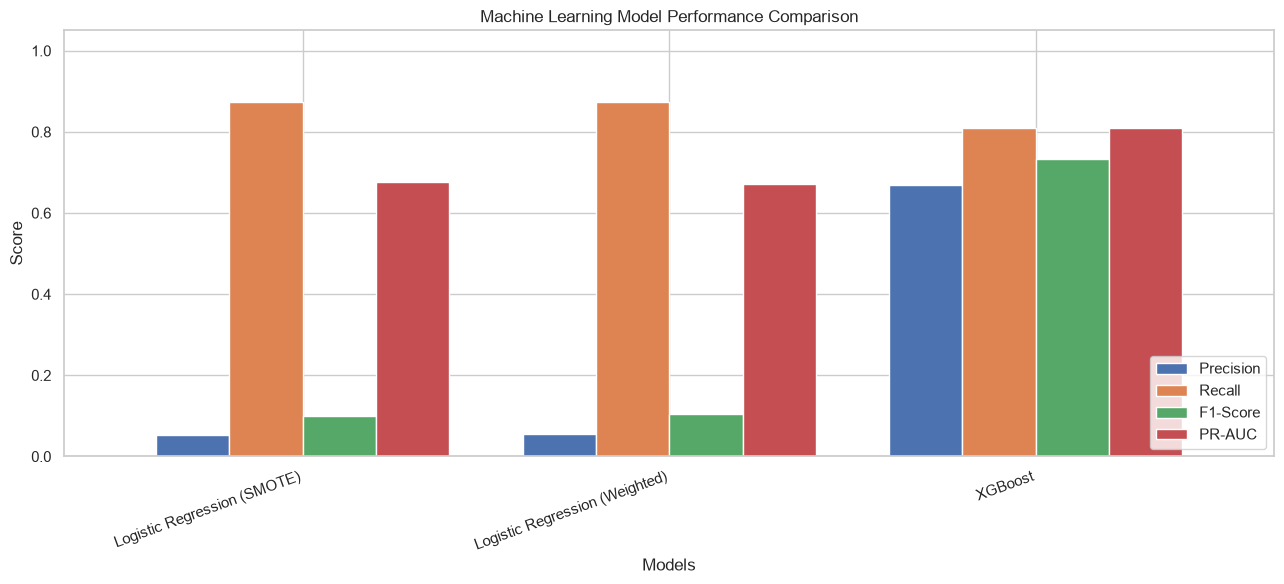

In [12]:
metrics = [
    "Precision",
    "Recall",
    "F1-Score",
    "PR-AUC"
]

results_plot = results_df.set_index("Model")[metrics]

results_plot.plot(
    kind="bar",
    figsize=(13, 6),
    width=0.8
)

plt.title("Machine Learning Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Models")
plt.xticks(rotation=20, ha="right")
plt.ylim(0, 1.05)
plt.legend(loc="lower right")
plt.tight_layout()

plt.savefig(
    FIGURES_PATH / "model_performance_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [10]:
results_df = results_df.sort_values(
    by="PR-AUC",
    ascending=False
)

results_df.to_csv(
    ROOT / "reports" / "model_evaluation_results.csv",
    index=False
)

print("Evaluation results saved successfully!")

display(results_df.round(4))

Evaluation results saved successfully!


,Model,Accuracy,Precision,Recall,F1-Score,PR-AUC
2,XGBoost,0.9990,0.6696,0.8105,0.7333,0.8095
0,Logistic Regression (SMOTE),0.9737,0.0530,0.8737,0.1000,0.6769
1,Logistic Regression (Weighted),0.9752,0.0562,0.8737,0.1057,0.6719
3,Isolation Forest,0.9968,0.1062,0.1263,0.1154,0.0665


In [13]:
import joblib
from pathlib import Path

# Set project paths
ROOT = Path.cwd()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

PROCESSED_PATH = ROOT / "data" / "processed"

# Load the original training and testing data
data = joblib.load(
    PROCESSED_PATH / "train_test_data.pkl"
)

X_train = data["X_train"]
y_train = data["y_train"]

X_test = data["X_test"]
y_test = data["y_test"]

print("Training data loaded successfully!")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

Training data loaded successfully!
X_train: (226980, 30)
y_train: (226980,)
X_test: (56746, 30)
y_test: (56746,)


In [14]:
from sklearn.model_selection import train_test_split

X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Sub-training:", X_subtrain.shape)
print("Validation:", X_val.shape)

Sub-training: (181584, 30)
Validation: (45396, 30)


In [15]:
from xgboost import XGBClassifier

# Calculate class imbalance ratio using sub-training data
negative_count = (y_subtrain == 0).sum()
positive_count = (y_subtrain == 1).sum()

scale_pos_weight = negative_count / positive_count

# Initialize validation model
xgb_validation = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    eval_metric="aucpr",
    random_state=42,
    n_jobs=-1
)

# Train the model
xgb_validation.fit(X_subtrain, y_subtrain)

print("Validation XGBoost model trained successfully!")

Validation XGBoost model trained successfully!


In [16]:
# Predict fraud probabilities on validation data
val_probabilities = xgb_validation.predict_proba(X_val)[:, 1]

print("Validation predictions generated!")
print("Total validation transactions:", len(val_probabilities))

print("\nSample fraud probabilities:")
print(val_probabilities[:10])

Validation predictions generated!
Total validation transactions: 45396

Sample fraud probabilities:
[3.3025102e-05 1.3923614e-04 8.6703374e-05 3.6847396e-05 4.4391505e-05
 1.3955502e-04 1.6057214e-05 3.1732721e-05 1.4155072e-05 6.2784795e-03]


In [17]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

threshold_results = []

for threshold in np.arange(0.1, 0.91, 0.05):

    val_predictions = (
        val_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": round(threshold, 2),

        "Precision": precision_score(
            y_val, val_predictions, zero_division=0
        ),

        "Recall": recall_score(
            y_val, val_predictions, zero_division=0
        ),

        "F1-Score": f1_score(
            y_val, val_predictions, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,Threshold,Precision,Recall,F1-Score
0,0.10,0.2702,0.8816,0.4136
1,0.15,0.3702,0.8816,0.5214
2,0.20,0.4621,0.8816,0.6063
3,0.25,0.5492,0.8816,0.6768
4,0.30,0.6091,0.8816,0.7204
5,0.35,0.6505,0.8816,0.7486
6,0.40,0.6907,0.8816,0.7746
7,0.45,0.7204,0.8816,0.7929
8,0.50,0.7857,0.8684,0.8250
9,0.55,0.8025,0.8553,0.8280


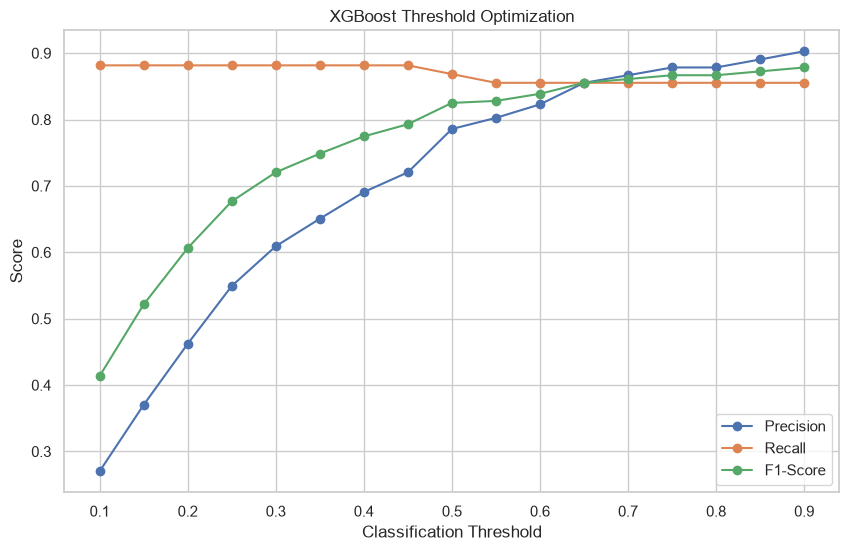

In [21]:
plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1-Score"],
    marker="o",
    label="F1-Score"
)

plt.title("XGBoost Threshold Optimization")
plt.xlabel("Classification Threshold")
plt.ylabel("Score")

plt.legend()
plt.grid(True)

plt.savefig(
    FIGURES_PATH / "threshold_optimization.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [18]:
best_row = threshold_df.loc[
    threshold_df["F1-Score"].idxmax()
]

print("Best threshold based on F1-score:")
print(best_row)

Best threshold based on F1-score:
Threshold    0.900000
Precision    0.902778
Recall       0.855263
F1-Score     0.878378
Name: 16, dtype: float64


In [23]:
high_threshold_results = []

for threshold in np.arange(0.91, 1.00, 0.01):

    val_predictions = (
        val_probabilities >= threshold
    ).astype(int)

    high_threshold_results.append({
        "Threshold": round(threshold, 2),

        "Precision": precision_score(
            y_val, val_predictions, zero_division=0
        ),

        "Recall": recall_score(
            y_val, val_predictions, zero_division=0
        ),

        "F1-Score": f1_score(
            y_val, val_predictions, zero_division=0
        )
    })

high_threshold_df = pd.DataFrame(high_threshold_results)

display(high_threshold_df.round(4))

,Threshold,Precision,Recall,F1-Score
0,0.91,0.9028,0.8553,0.8784
1,0.92,0.9028,0.8553,0.8784
2,0.93,0.9028,0.8553,0.8784
3,0.94,0.9028,0.8553,0.8784
4,0.95,0.9028,0.8553,0.8784
5,0.96,0.9155,0.8553,0.8844
6,0.97,0.9286,0.8553,0.8904
7,0.98,0.9265,0.8289,0.8750
8,0.99,0.9403,0.8289,0.8811


In [19]:
all_threshold_results = pd.concat(
    [threshold_df, high_threshold_df],
    ignore_index=True
)

best_row = all_threshold_results.loc[
    all_threshold_results["F1-Score"].idxmax()
]

print("Best threshold across all experiments:")
print(best_row)

NameError: name 'high_threshold_df' is not defined

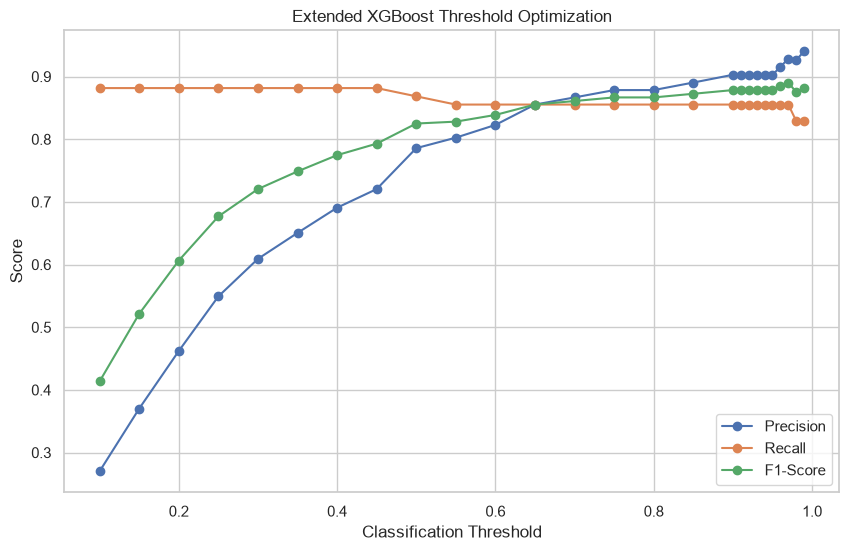

In [25]:
plt.figure(figsize=(10, 6))

plt.plot(
    all_threshold_results["Threshold"],
    all_threshold_results["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    all_threshold_results["Threshold"],
    all_threshold_results["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    all_threshold_results["Threshold"],
    all_threshold_results["F1-Score"],
    marker="o",
    label="F1-Score"
)

plt.title("Extended XGBoost Threshold Optimization")
plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.legend()
plt.grid(True)

plt.savefig(
    FIGURES_PATH / "extended_threshold_optimization.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [20]:
from xgboost import XGBClassifier

# Calculate class imbalance
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

final_weight = negative_count / positive_count

# Initialize final XGBoost model
final_xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=final_weight,
    eval_metric="aucpr",
    random_state=42,
    n_jobs=-1
)

# Train using complete training dataset
final_xgb_model.fit(X_train, y_train)

print("Final XGBoost model trained successfully!")

Final XGBoost model trained successfully!


In [21]:
# Get fraud probabilities
test_probabilities = final_xgb_model.predict_proba(X_test)[:, 1]

# Apply optimized threshold
best_threshold = 0.97

final_predictions = (
    test_probabilities >= best_threshold
).astype(int)

print("Final predictions generated!")

Final predictions generated!


In [22]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    classification_report
)

print("FINAL XGBOOST MODEL PERFORMANCE")
print("--------------------------------")

print("Threshold:", best_threshold)

print("Accuracy:",
      accuracy_score(y_test, final_predictions))

print("Precision:",
      precision_score(y_test, final_predictions))

print("Recall:",
      recall_score(y_test, final_predictions))

print("F1-Score:",
      f1_score(y_test, final_predictions))

print("PR-AUC:",
      average_precision_score(y_test, test_probabilities))

print("\nClassification Report:")
print(classification_report(y_test, final_predictions))

FINAL XGBOOST MODEL PERFORMANCE
--------------------------------
Threshold: 0.97
Accuracy: 0.9995241955380115
Precision: 0.9594594594594594
Recall: 0.7473684210526316
F1-Score: 0.8402366863905325
PR-AUC: 0.8095433695421632

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.96      0.75      0.84        95

    accuracy                           1.00     56746
   macro avg       0.98      0.87      0.92     56746
weighted avg       1.00      1.00      1.00     56746



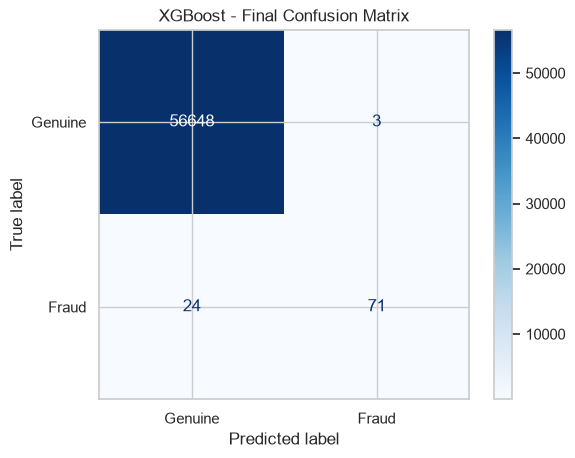

In [29]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, final_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Genuine", "Fraud"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("XGBoost - Final Confusion Matrix")
plt.savefig(
    FIGURES_PATH / "final_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [30]:
import joblib

joblib.dump(
    final_xgb_model,
    ROOT / "models" / "final_xgboost_model.pkl"
)

print("Final XGBoost model saved successfully!")

Final XGBoost model saved successfully!


In [31]:
%pip install shap

   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   --------------------------- ------------ 524.3/751.9 kB 3.4 MB/s eta 0:00:01
   ---------------------------------------- 751.9/751.9 kB 3.1 MB/s  0:00:00

   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   ---------------------------------------- 2/2 [shap]

Note: you may need to restart the kernel to use updated packages.


In [23]:
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from pathlib import Path

# Project paths
ROOT = Path.cwd()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

FIGURES_PATH = ROOT / "reports" / "figures"
FIGURES_PATH.mkdir(parents=True, exist_ok=True)

# Load final model
final_xgb_model = joblib.load(
    ROOT / "models" / "final_xgboost_model.pkl"
)

print("Final XGBoost model loaded successfully!")

c:\Users\HP\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Final XGBoost model loaded successfully!


In [24]:
# Initialize SHAP TreeExplainer
explainer = shap.TreeExplainer(final_xgb_model)

print("SHAP explainer initialized successfully!")

SHAP explainer initialized successfully!


In [25]:
# Select a reproducible sample
sample_size = min(1000, len(X_test))

X_shap = X_test.sample(
    n=sample_size,
    random_state=42
)

# Calculate SHAP values
shap_values = explainer(X_shap)

print("SHAP values calculated successfully!")
print("Explained transactions:", len(X_shap))
print("Number of features:", X_shap.shape[1])

SHAP values calculated successfully!
Explained transactions: 1000
Number of features: 30


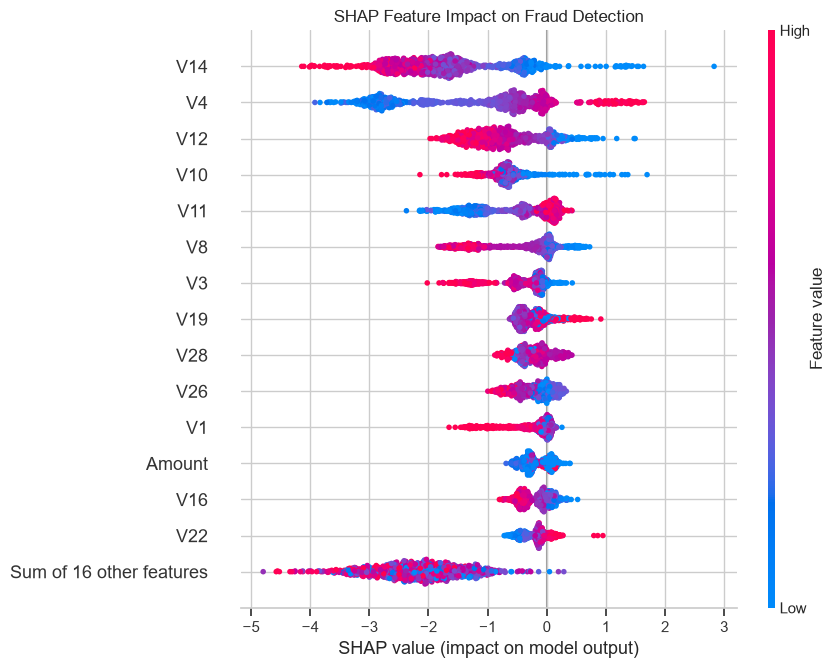

In [35]:
plt.figure(figsize=(12, 7))

shap.plots.beeswarm(
    shap_values,
    max_display=15,
    show=False
)

plt.title("SHAP Feature Impact on Fraud Detection")

plt.savefig(
    FIGURES_PATH / "shap_beeswarm.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

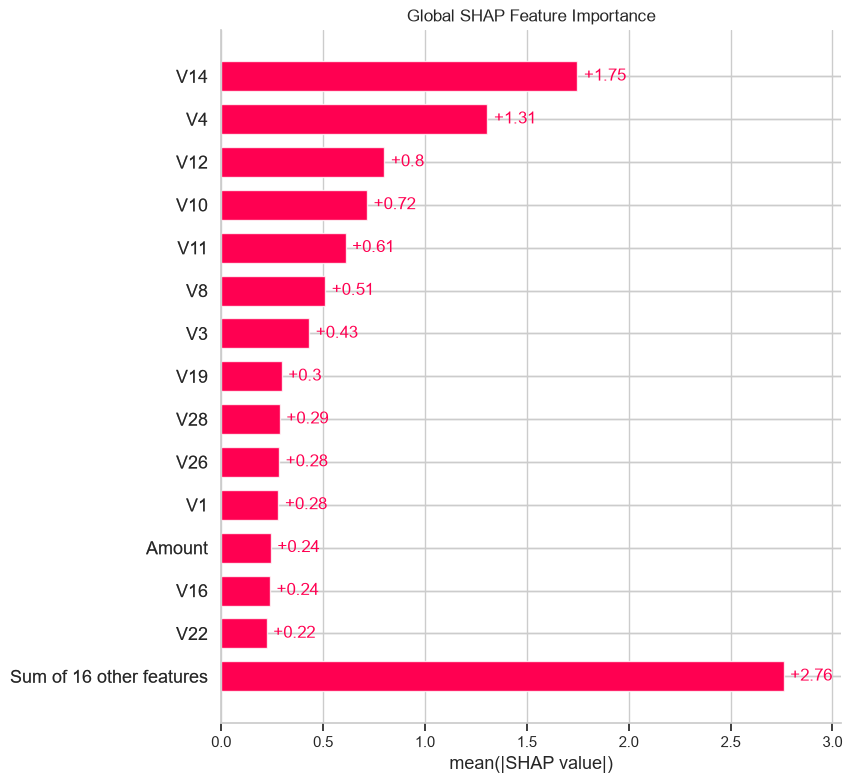

In [26]:
plt.figure(figsize=(10, 6))

shap.plots.bar(
    shap_values,
    max_display=15,
    show=False
)

plt.title("Global SHAP Feature Importance")

plt.savefig(
    FIGURES_PATH / "shap_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [27]:
# Find transactions flagged as fraud
flagged_indices = np.where(final_predictions == 1)[0]

if len(flagged_indices) > 0:

    # Select the highest-probability flagged transaction
    fraud_idx = flagged_indices[
        np.argmax(test_probabilities[flagged_indices])
    ]

else:

    # If none are flagged, select the highest-risk transaction
    fraud_idx = np.argmax(test_probabilities)

print("Transaction index:", fraud_idx)

print("Fraud probability:",
      round(test_probabilities[fraud_idx], 4))

print("Classification:",
      "Fraud" if final_predictions[fraud_idx] == 1
      else "Genuine")

Transaction index: 50775
Fraud probability: 0.9999
Classification: Fraud


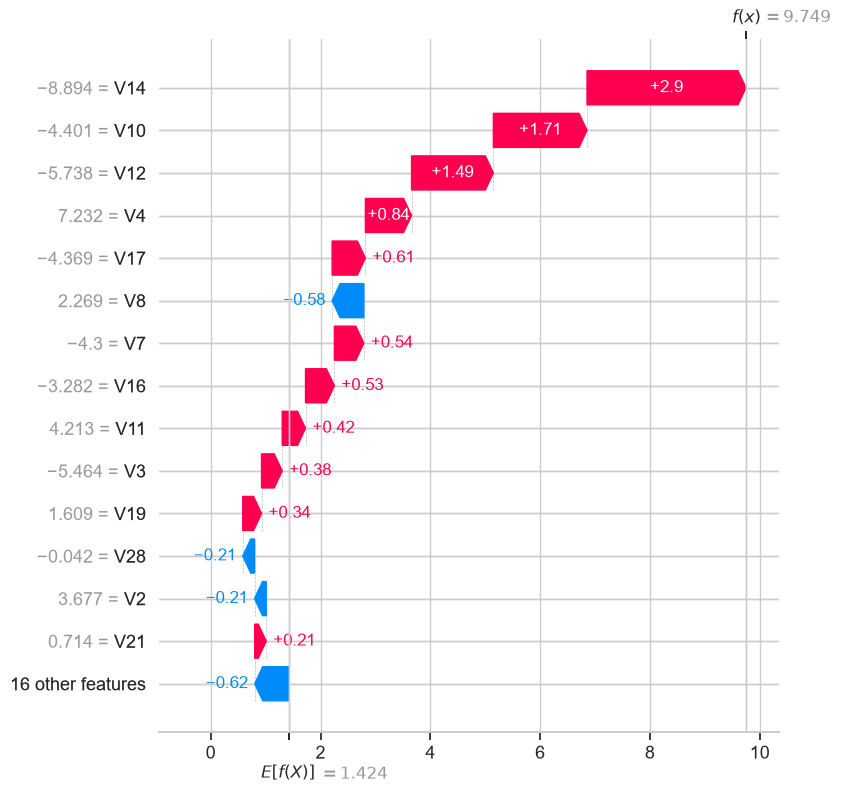

In [38]:
# Select individual transaction
individual_transaction = X_test.iloc[[fraud_idx]]

# Calculate SHAP explanation
individual_shap = explainer(individual_transaction)

# Generate waterfall plot
shap.plots.waterfall(
    individual_shap[0],
    max_display=15
)

In [28]:
print("SHAP visualizations saved:")
print(FIGURES_PATH / "shap_beeswarm.png")
print(FIGURES_PATH / "shap_feature_importance.png")

print("\nSHAP explainability completed!")

SHAP visualizations saved:
c:\Users\HP\Documents\AI,ML3\digital-payment-risk\reports\figures\shap_beeswarm.png
c:\Users\HP\Documents\AI,ML3\digital-payment-risk\reports\figures\shap_feature_importance.png

SHAP explainability completed!


In [29]:

import joblib
from pathlib import Path

# Locate the models folder
possible_paths = [
    Path("models"),
    Path("../models")
]

MODELS_PATH = next(
    (path for path in possible_paths if path.exists()),
    None
)

if MODELS_PATH is None:
    raise FileNotFoundError("Models folder not found!")

# Load final XGBoost model
final_model = joblib.load(
    MODELS_PATH / "final_xgboost_model.pkl"
)

# Load saved scaler
scaler = joblib.load(
    MODELS_PATH / "standard_scaler.pkl"
)

print("Models loaded successfully!")

print("\nXGBoost Model:")
print(final_model)

print("\nModel expected features:",
      final_model.n_features_in_)

print("\nScaler expected features:",
      scaler.n_features_in_)

print("\nModel classes:",
      final_model.classes_)


Models loaded successfully!

XGBoost Model:
XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='aucpr', feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.05, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=4,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=300,
              n_jobs=-1, num_parallel_tree=None, ...)

Model expected features: 30

Scaler expected features: 2

Model classes: [0 1]


In [31]:

# Check the features used by the trained model
print("XGBoost expected features:")
print(final_model.n_features_in_)

print("\nScaler expected features:")
print(scaler.n_features_in_)

# Check feature names from training data
print("\nTraining feature columns:")

print(X_train.columns.tolist())


XGBoost expected features:
30

Scaler expected features:
2

Training feature columns:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount']
